# Chapter 18: The Bootstrap and Resampling Methods

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch18/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ibrahimguney/statistical-theory/blob/main/notebooks/ch_18.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## Bootstrap Standard Error of the Median

*Source file:* `code/ch18/c18_1_bootstrap_se_of_median.py`

Observed median = 0.6487 (true ln2 = 0.6931)
Median SE: bootstrap = 0.1955 | true (MC) = 0.1406 | asymptotic 1/sqrt(n) = 0.1414
Mean SE: bootstrap = 0.1009 | plug-in formula sigma_hat/sqrt(n) = 0.1006
Proportion of distinct observations in a bootstrap sample ≈ 0.632 (1-1/e = 0.632)
Number of distinct values in the bootstrap distribution of the median: 121 / 4000


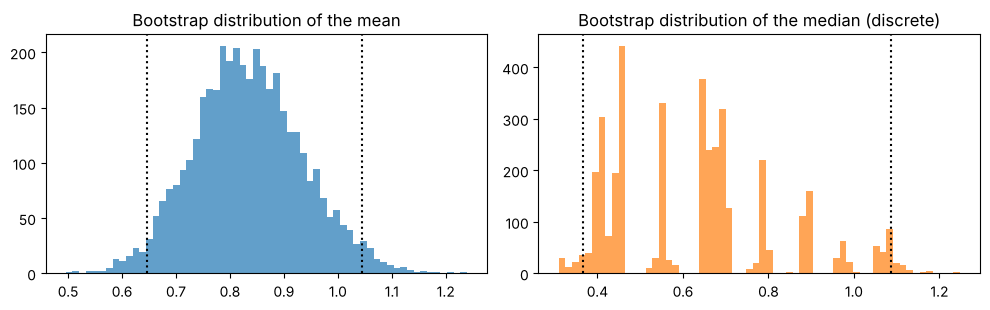

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n, B = 50, 4000
x = rng.exponential(1.0, size=n)
idx = rng.integers(0, n, size=(B, n))
med_star = np.median(x[idx], axis=1)
mean_star = x[idx].mean(axis=1)

true_se = np.median(rng.exponential(1.0, size=(200_000, n)), axis=1).std()
print(f"Observed median = {np.median(x):.4f} (true ln2 = {np.log(2):.4f})")
print(f"Median SE: bootstrap = {med_star.std(ddof=1):.4f} | true (MC) = {true_se:.4f} | asymptotic 1/sqrt(n) = {1/np.sqrt(n):.4f}")
print(f"Mean SE: bootstrap = {mean_star.std(ddof=1):.4f} | plug-in formula sigma_hat/sqrt(n) = {x.std()/np.sqrt(n):.4f}")
print(f"Proportion of distinct observations in a bootstrap sample ≈ {np.mean([np.unique(r).size for r in idx[:500]])/n:.3f} (1-1/e = {1-np.exp(-1):.3f})")
print(f"Number of distinct values in the bootstrap distribution of the median: {np.unique(med_star).size} / {B}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(mean_star, bins=60, color="tab:blue", alpha=0.7); ax[0].set_title(r"Bootstrap distribution of the mean")
ax[1].hist(med_star, bins=60, color="tab:orange", alpha=0.7); ax[1].set_title(r"Bootstrap distribution of the median (discrete)")
for a, s in zip(ax, [mean_star, med_star]):
    for q in np.percentile(s, [2.5, 97.5]):
        a.axvline(q, color="k", ls=":")
fig.tight_layout(); fig.savefig("bootstrap_dagilim.pdf")

## Coverage of Bootstrap Confidence Intervals

We generate $M=2000$ data sets of size $n=20$ from the Exp(1) distribution and in each construct five different $95%$ intervals for $\mu$. The skewed distribution and the small $n$ bring out the differences between the methods.

*Source file:* `code/ch18/c18_2_coverage_of_bootstrap_intervals.py`

In [3]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
n, B, M, mu = 20, 999, 2000, 1.0
a = 0.05; zl, zu = stats.norm.ppf(a/2), stats.norm.ppf(1 - a/2)
tc = stats.t.ppf(1 - a/2, n - 1)
methods = ["t (classic)", "Percentile", "Basic", "Bootstrap-t", "BCa"]
covers = {k: 0 for k in methods}; left = {k: 0 for k in methods}; length = {k: 0.0 for k in methods}
for _ in range(M):
    x = rng.exponential(mu, n)
    xb, s = x.mean(), x.std(ddof=1); se = s/np.sqrt(n)
    xs = x[rng.integers(0, n, (B, n))]
    m_s, se_s = xs.mean(1), xs.std(1, ddof=1)/np.sqrt(n)
    ql, qu = np.percentile(m_s, [2.5, 97.5])
    t_s = (m_s - xb)/se_s
    tl, tu = np.percentile(t_s, [2.5, 97.5])
    z0 = stats.norm.ppf(np.mean(m_s < xb))
    jack = (x.sum() - x)/(n - 1); d = jack.mean() - jack
    acc = np.sum(d**3)/(6*np.sum(d**2)**1.5)
    a1 = stats.norm.cdf(z0 + (z0 + zl)/(1 - acc*(z0 + zl)))
    a2 = stats.norm.cdf(z0 + (z0 + zu)/(1 - acc*(z0 + zu)))
    iv = {"t (classic)": (xb - tc*se, xb + tc*se), "Percentile": (ql, qu), "Basic": (2*xb - qu, 2*xb - ql),
          "Bootstrap-t": (xb - tu*se, xb - tl*se), "BCa": tuple(np.percentile(m_s, [100*a1, 100*a2]))}
    for k, (L, U) in iv.items():
        covers[k] += (L <= mu <= U); left[k] += (U < mu); length[k] += U - L
print(f"{'Method':12s} | coverage | interval left of mu | mean length")
for k in methods:
    print(f"{k:12s} |  {covers[k]/M:.4f}  |       {left[k]/M:.4f}        |   {length[k]/M:.4f}")

Method       | coverage | interval left of mu | mean length
t (classic)  |  0.9250  |       0.0685        |   0.9032
Percentile   |  0.9060  |       0.0760        |   0.8157
Basic        |  0.8890  |       0.1000        |   0.8157
Bootstrap-t  |  0.9385  |       0.0410        |   1.0531
BCa          |  0.9115  |       0.0570        |   0.8623


## Failure: The Maximum of $\text{Uniform}(0,\theta)$

*Source file:* `code/ch18/c18_3_failure_uniform_maximum.py`

In [4]:
import numpy as np

rng = np.random.default_rng(42)
theta, n, B = 1.0, 50, 20_000
x = rng.uniform(0, theta, n)
m = x.max()
np_boot = x[rng.integers(0, n, (B, n))].max(1)                 # nonparametric
p_boot = rng.uniform(0, m, (B, n)).max(1)                       # parametric
true_max = rng.uniform(0, theta, (B, n)).max(1)
print(f"P*(X*_(n) = X_(n)) = {np.mean(np_boot == m):.4f} | theory 1-(1-1/n)^n = {1-(1-1/n)**n:.4f}")
for name, s, ref in [("True distribution   ", n*(theta - true_max)/theta, None),
                   ("Nonparametric       ", n*(m - np_boot)/m, None),
                   ("Parametric bootstrap", n*(m - p_boot)/m, None)]:
    q = np.percentile(s, [25, 50, 75])
    print(f"{name} | n(theta-max)/theta: P(=0)={np.mean(s == 0):.3f} | quartiles={np.round(q, 3)} (Exp(1): [0.288 0.693 1.386])")

P*(X*_(n) = X_(n)) = 0.6410 | theory 1-(1-1/n)^n = 0.6358
True distribution    | n(theta-max)/theta: P(=0)=0.000 | quartiles=[0.284 0.678 1.346] (Exp(1): [0.288 0.693 1.386])
Nonparametric        | n(theta-max)/theta: P(=0)=0.641 | quartiles=[0.    0.    0.252] (Exp(1): [0.288 0.693 1.386])
Parametric bootstrap | n(theta-max)/theta: P(=0)=0.000 | quartiles=[0.289 0.688 1.381] (Exp(1): [0.288 0.693 1.386])


## Jackknife and Permutation Test

*Source file:* `code/ch18/c18_4_jackknife_permutation_test.py`

In [5]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
x = rng.normal(5, 2, 15)
n = x.size
plug = x.var()                                         # sigma_hat^2 (1/n)
jack = np.array([np.delete(x, i).var() for i in range(n)])
jk = n*plug - (n - 1)*jack.mean()
print(f"sigma_hat^2 = {plug:.5f} | jackknife-corrected = {jk:.5f} | S^2 = {x.var(ddof=1):.5f}")

# A known failure of the jackknife: the SE of the median
med_j = np.array([np.median(np.delete(x, i)) for i in range(n)])
print(f"Number of distinct median jackknife values: {np.unique(med_j).size} (n={n}) -> SE estimate unreliable")

# Permutation test: two skewed samples, with a real difference
def perm_test(a, b, B=9999):
    z = np.r_[a, b]; T0 = b.mean() - a.mean()
    T = np.array([np.diff([p[:a.size].mean(), p[a.size:].mean()])[0]
                  for p in (rng.permutation(z) for _ in range(B))])
    return (1 + np.sum(np.abs(T) >= abs(T0)))/(B + 1)
a = rng.lognormal(0.0, 1.0, 12); b = rng.lognormal(0.8, 1.0, 12)
print(f"Permutation p = {perm_test(a, b):.4f} | Welch t-test p = {stats.ttest_ind(a, b, equal_var=False).pvalue:.4f}")

# Type I error under H0 (small, skewed samples)
rej_p = rej_t = 0; K = 1000
for _ in range(K):
    a = rng.lognormal(0, 1, 8); b = rng.lognormal(0, 1, 8)
    rej_p += perm_test(a, b, B=499) <= 0.05
    rej_t += stats.ttest_ind(a, b, equal_var=False).pvalue <= 0.05
print(f"rejection rate under H0 (target 0.05): permutation = {rej_p/K:.3f} | Welch t = {rej_t/K:.3f}")

sigma_hat^2 = 3.15749 | jackknife-corrected = 3.38303 | S^2 = 3.38303
Number of distinct median jackknife values: 3 (n=15) -> SE estimate unreliable
Permutation p = 0.0119 | Welch t-test p = 0.0841


rejection rate under H0 (target 0.05): permutation = 0.057 | Welch t = 0.026


## Real Data: Law Schools and the Bootstrap of a Correlation

The data Efron and Tibshirani used to introduce the bootstrap : the average LSAT score and undergraduate GPA of 82 US law schools, and a random sample of 15 schools from this population. These data offer a rare situation: since the population is known, the *true* sampling distribution that the bootstrap tries to approximate can also be computed. The code computes the bootstrap standard error of the sample correlation $r$ and four $95%$ intervals: percentile, basic, BCa, and the Fisher $z$ interval based on bivariate normality (Example 12.23). It then draws 15 schools from the population without replacement to find the true standard deviation of $r$.

*Source file:* `code/ch18/c18_5_law_schools_real_data.py`

In [6]:
import numpy as np
from scipy import stats

# Efron and Tibshirani (1993): average LSAT score and undergraduate GPA of 82 US law schools
# (the population), and a sample of 15 schools drawn from it. Source: R package bootstrap.
lsat15 = np.array([
    576, 635, 558, 578, 666, 580, 555, 661, 651, 605, 653, 575, 545, 572, 594,
])
gpa15 = np.array([
    3.39, 3.3, 2.81, 3.03, 3.44, 3.07, 3.0, 3.43, 3.36, 3.13, 3.12, 2.74, 2.76, 2.88, 2.96,
])
lsat82 = np.array([
    622, 542, 579, 653, 606, 576, 620, 615, 553, 607, 558, 596, 635, 581, 661, 547, 599, 646,
    622, 611, 546, 614, 628, 575, 662, 627, 608, 632, 587, 581, 605, 704, 477, 591, 578, 572,
    615, 606, 603, 535, 595, 575, 573, 644, 545, 645, 651, 562, 609, 555, 586, 580, 594, 594,
    560, 641, 512, 631, 597, 621, 617, 637, 572, 610, 562, 635, 614, 546, 598, 666, 570, 570,
    605, 565, 686, 608, 595, 590, 558, 611, 564, 575,
])
gpa82 = np.array([
    3.23, 2.83, 3.24, 3.12, 3.09, 3.39, 3.1, 3.4, 2.97, 2.91, 3.11, 3.24, 3.3, 3.22, 3.43, 2.91,
    3.23, 3.47, 3.15, 3.33, 2.99, 3.19, 3.03, 3.01, 3.39, 3.41, 3.04, 3.29, 3.16, 3.17, 3.13,
    3.36, 2.57, 3.02, 3.03, 2.88, 3.37, 3.2, 3.23, 2.98, 3.11, 2.92, 2.85, 3.38, 2.76, 3.27,
    3.36, 3.19, 3.17, 3.0, 3.11, 3.07, 2.96, 3.05, 2.93, 3.28, 3.01, 3.21, 3.32, 3.24, 3.03,
    3.33, 3.08, 3.13, 3.01, 3.3, 3.15, 2.82, 3.2, 3.44, 3.01, 2.92, 3.45, 3.15, 3.5, 3.16, 3.19,
    3.15, 2.81, 3.16, 3.02, 2.74,
])

def corr(a, b):                                             # row-wise correlation
    a = a - a.mean(axis=-1, keepdims=True); b = b - b.mean(axis=-1, keepdims=True)
    return (a * b).sum(-1) / np.sqrt((a * a).sum(-1) * (b * b).sum(-1))

rng = np.random.default_rng(42)
n, B = 15, 10_000
r = corr(lsat15, gpa15)
idx = rng.integers(0, n, size=(B, n))
r_b = corr(lsat15[idx], gpa15[idx])
print(f"sample r = {r:.4f} | bootstrap SE = {r_b.std(ddof=1):.4f}, bias = {r_b.mean() - r:+.4f}")
ql, qu = np.percentile(r_b, [2.5, 97.5])
z0 = stats.norm.ppf(np.mean(r_b < r))
jack = np.array([corr(np.delete(lsat15, i), np.delete(gpa15, i)) for i in range(n)])
dj = jack.mean() - jack
a = np.sum(dj**3) / (6 * np.sum(dj**2)**1.5)
zl, zu = stats.norm.ppf([0.025, 0.975])
a1 = stats.norm.cdf(z0 + (z0 + zl) / (1 - a * (z0 + zl)))
a2 = stats.norm.cdf(z0 + (z0 + zu) / (1 - a * (z0 + zu)))
z = np.arctanh(r)
print(f"95% intervals: percentile [{ql:.3f}, {qu:.3f}] | basic [{2*r - qu:.3f}, {2*r - ql:.3f}]"
      f" | BCa [{np.percentile(r_b, 100*a1):.3f}, {np.percentile(r_b, 100*a2):.3f}]"
      f" | Fisher z [{np.tanh(z - 1.96/np.sqrt(n - 3)):.3f}, {np.tanh(z + 1.96/np.sqrt(n - 3)):.3f}]")
print(f"BCa constants: z0 = {z0:.3f}, acceleration a = {a:.3f}")

# True sampling distribution: drawing 15 schools from the population without replacement
R = 100_000
pick = np.argsort(rng.random((R, 82)), axis=1)[:, :n]
r_g = corr(lsat82[pick], gpa82[pick])
print(f"population rho = {corr(lsat82, gpa82):.4f} | true SD(r) = {r_g.std():.4f} | E(r) = {r_g.mean():.4f}")

sample r = 0.7764 | bootstrap SE = 0.1354, bias = -0.0058
95% intervals: percentile [0.456, 0.962] | basic [0.591, 1.097] | BCa [0.317, 0.943] | Fisher z [0.439, 0.922]
BCa constants: z0 = -0.105, acceleration a = -0.076


population rho = 0.7600 | true SD(r) = 0.1185 | E(r) = 0.7486
